# **PROJECT 3: SPAM CLASSIFIER**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB

In [4]:
df=pd.read_csv("SMSSpamCollection",sep="\t",names=["label","message"])

In [5]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [6]:
df.shape

(5572, 2)

In [7]:
for i in range(10):
    print(df.iloc[i,-1])
    print()

Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Ok lar... Joking wif u oni...

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

U dun say so early hor... U c already then say...

Nah I don't think he goes to usf, he lives around here though

FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv

Even my brother is not like to speak with me. They treat me like aids patent.

As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune

WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.

Had your mobile 11 months or more? U

In [9]:
#STEP 1:Data Cleaning
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

In [11]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\vaibh\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [12]:
sn=SnowballStemmer("english")
stop=set(stopwords.words('english'))

In [22]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\vaibh\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [29]:
def clean_text(sms):
    sms=sms.lower()
    sms=re.sub("[^a-zA-Z0-9]"," ",sms)
    sms=nltk.word_tokenize(sms)
    sms= [t for t in sms if len(t)>1] #Reducing Dimensionality
    sms=[sn.stem(word) for word in sms if word not in stop]
    sms= " ".join(sms)
    return sms

In [30]:
clean_text("Get Free playing Unlimited,.<>>? play Data 100GB...at Rs.0")

'get free play unlimit play data 100gb rs'

In [32]:
print(df.columns)

Index(['label', 'message'], dtype='object')


In [35]:
df['clean_text']=df['message'].apply(clean_text)

In [36]:
df.head()

,label,message,clean_text
0,ham,go jurong point crazi avail bugi great world l...,go jurong point crazi avail bugi great world l...
1,ham,ok lar joke wif oni,ok lar joke wif oni
2,spam,free entri wkli comp win fa cup final tkts 21s...,free entri wkli comp win fa cup final tkts 21s...
3,ham,dun say earli hor alreadi say,dun say ear hor alreadi say
4,ham,nah think goe usf live around though,nah think goe usf live around though


In [38]:
#STEP 2:WORDCLOUD
!pip install wordcloud


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
from wordcloud import WordCloud

In [42]:
df['label']=='ham'

0        True
1        True
2       False
3        True
4        True
        ...  
5567    False
5568     True
5569     True
5570     True
5571     True
Name: label, Length: 5572, dtype: bool

In [43]:
df[df['label']=='ham']

,label,message,clean_text
0,ham,go jurong point crazi avail bugi great world l...,go jurong point crazi avail bugi great world l...
1,ham,ok lar joke wif oni,ok lar joke wif oni
3,ham,dun say earli hor alreadi say,dun say ear hor alreadi say
4,ham,nah think goe usf live around though,nah think goe usf live around though
6,ham,even brother like speak treat like aid patent,even brother like speak treat like aid patent
...,...,...,...
5565,ham,huh lei,huh lei
5568,ham,go esplanad fr home,go esplanad fr home
5569,ham,piti mood suggest,piti mood suggest
5570,ham,guy bitch act like interest buy someth els nex...,guy bitch act like interest buy someth el next...


In [44]:
hamdata=df[df['label']=='ham']
hamdata=hamdata['clean_text']

In [45]:
hamdata

0       go jurong point crazi avail bugi great world l...
1                                     ok lar joke wif oni
3                             dun say ear hor alreadi say
4                    nah think goe usf live around though
6           even brother like speak treat like aid patent
                              ...                        
5565                                              huh lei
5568                                  go esplanad fr home
5569                                    piti mood suggest
5570    guy bitch act like interest buy someth el next...
5571                                       rofl true name
Name: clean_text, Length: 4825, dtype: object

In [57]:
def wordCloud(data):
    words=' '.join(data)
    wc= WordCloud()
    wc=wc.generate(words)
    plt.figure(figsize=(10,8))
    plt.imshow(wc.to_image())
    plt.axis('off')
    plt.show()

Hamdata words:


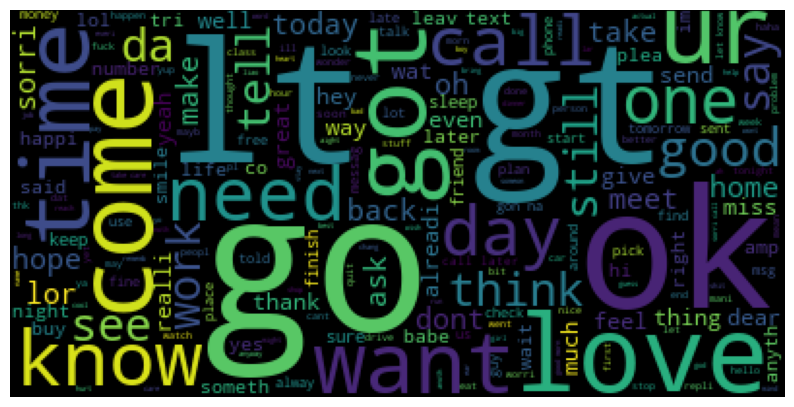

In [65]:
print("Hamdata words:")
wordCloud(hamdata)

In [66]:
spamdata=df[df['label']=='spam']
spamdata=spamdata['clean_text']

Spamdata words:


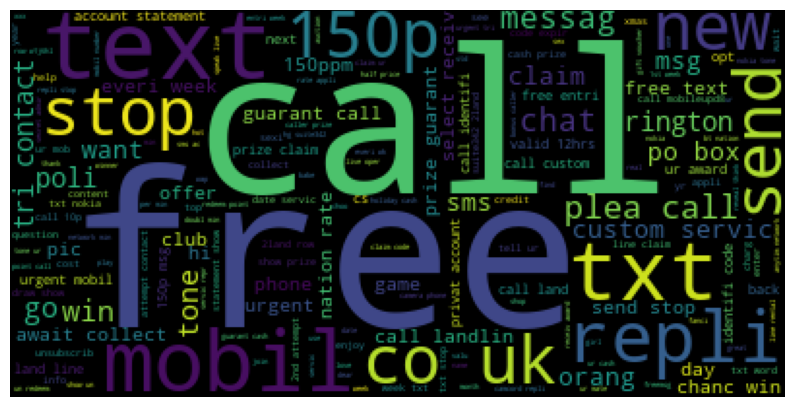

In [70]:
print("Spamdata words:")
wordCloud(spamdata)

In [71]:
#Step 3:Featurization
from sklearn.feature_extraction.text import CountVectorizer

In [75]:
cv=CountVectorizer(max_features=5000)

In [76]:
X=cv.fit_transform(df['clean_text']).toarray()

In [77]:
X.shape

(5572, 5000)

In [78]:
df['label']

0        ham
1        ham
2       spam
3        ham
4        ham
        ... 
5567    spam
5568     ham
5569     ham
5570     ham
5571     ham
Name: label, Length: 5572, dtype: object

In [80]:
y=pd.get_dummies(df['label'])
y=y['spam'].values

In [81]:
y

array([False, False,  True, ..., False, False, False])

In [82]:
#Step 4:Model Building
from sklearn.model_selection import train_test_split

In [84]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [86]:
from sklearn.naive_bayes import MultinomialNB

In [87]:
model=MultinomialNB()
model.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [89]:
y_pred=model.predict(X_test)

In [90]:
y_test,y_pred

(array([False,  True, False, ..., False,  True, False]),
 array([False,  True, False, ..., False,  True, False]))

In [91]:
pd.DataFrame({'Actual':y_test, 'Predicted':y_pred})

,Actual,Predicted
0,False,False
1,True,True
2,False,False
3,False,False
4,False,False
...,...,...
1110,False,False
1111,False,False
1112,False,False
1113,True,True


In [92]:
#Step 5:Model Evaluation
print("Accuracy on Training Data:")
print(model.score(X_train, y_train))

Accuracy on Trainind Data:
0.991249719542293


In [93]:
print("Accuracy on Test Data:")
print(model.score(X_test, y_test))

Accuracy on Test Data:
0.9865470852017937


In [94]:
from sklearn.metrics import confusion_matrix,f1_score,classification_report

In [95]:
confusion_matrix(y_test,y_pred)

array([[948,   7],
       [  8, 152]], dtype=int64)

In [96]:
print('classification_report')
print(classification_report(y_test,y_pred))

classification_report
              precision    recall  f1-score   support

       False       0.99      0.99      0.99       955
        True       0.96      0.95      0.95       160

    accuracy                           0.99      1115
   macro avg       0.97      0.97      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [97]:
f1_score(y_test,y_pred)

0.9529780564263323